# 07. GridSearchCV vs RandomizedSearchCV (report appendix 1)
- 최종 모델(Random Forest)의 하이퍼파라미터 탐색 방법 두 가지를 같은 조건에서 비교
  · GridSearchCV      : 03번 "Random Forest (regularized)"와 같은 그리드, 54개 조합을 모두 시도
  · RandomizedSearchCV: 더 넓은 연속 범위에서 N_ITER개 조합만 무작위로 뽑아 시도
- RandomizedSearchCV는 수업 노트북에 없는 기능. 예시 보고서의 부록이 두 탐색 방법의 비교이므로,
  "조합을 모두 시도하는 방법"과 "일부만 뽑아 시도하는 방법"의 성능·시간 차이를 확인하기 위해 사용
- 데이터·분할·교차검증(TimeSeriesSplit)·평가 지표는 03번과 동일
사전설치 : pip install pandas scikit-learn scipy matplotlib

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import randint
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, auc, classification_report, roc_curve
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 노트북에는 __file__이 없으므로 실행 위치(code 폴더 또는 ML 폴더)로 기준 폴더를 정함
BASE_DIR = (Path.cwd().parent if Path.cwd().name == "code" else Path.cwd())
DATA_DIR = BASE_DIR / "데이터_csv"
FIG_DIR = BASE_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)
RESULT_PATH = DATA_DIR / "results_search_comparison.csv"

In [2]:
# [CONFIG]
TARGET = "outflow"
CAT_FEATURES = ["dong", "month"]
NUM_FEATURES = [
    "price_m2",
    "price_chg_1m", "price_chg_3m",
    "price_chg_1m_lag2", "price_chg_1m_lag3",
    "trade_cnt", "trade_cnt_3m",
    "new_ratio", "build_year_avg",
    "pop_chg_rate_lag1", "population_lag1", "hh_size_lag1",
]
TRAIN_END = "2025-09"
THRESHOLD = 0.5
RANDOM_STATE = 42
N_SPLITS = 4
VALID_MONTHS = 3
SCORING = "roc_auc"
N_JOBS = -1

# GridSearchCV: 03번 2차 탐색과 같은 그리드 (2 × 3 × 3 × 3 = 54개 조합)
PARAM_GRID = {
    "model__n_estimators": [200, 500],
    "model__max_depth": [2, 3, 4],
    "model__min_samples_split": [10, 20, 40],
    "model__min_samples_leaf": [5, 10, 20],
}
# RandomizedSearchCV: 정수 범위에서 무작위로 뽑음 (randint(a, b)는 a 이상 b 미만)
PARAM_DIST = {
    "model__n_estimators": randint(100, 501),
    "model__max_depth": randint(2, 7),
    "model__min_samples_split": randint(5, 61),
    "model__min_samples_leaf": randint(2, 31),
}
N_ITER = 20             # 무작위로 시도할 조합 수

In [3]:
# Load data and split by time (03번과 동일)
df = pd.read_csv(DATA_DIR / "영통구_행정동별_월별_학습데이터셋.csv")
df = df.dropna(subset=CAT_FEATURES + NUM_FEATURES)
df = df.sort_values(["ym", "dong"]).reset_index(drop=True)
train = df[df["ym"] <= TRAIN_END].reset_index(drop=True)
test = df[df["ym"] > TRAIN_END].reset_index(drop=True)
X_train, y_train = train[CAT_FEATURES + NUM_FEATURES], train[TARGET]
X_test, y_test = test[CAT_FEATURES + NUM_FEATURES], test[TARGET]

n_dongs = train["dong"].nunique()
CV = TimeSeriesSplit(n_splits=N_SPLITS, test_size=n_dongs * VALID_MONTHS)


def evaluate(y_true, y_prob):
    y_pred = (y_prob >= THRESHOLD).astype(int)
    report = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": report["1"]["precision"],
        "Recall": report["1"]["recall"],
        "F1": report["1"]["f1-score"],
        "ROC-AUC": auc(fpr, tpr),
    }


def make_pipeline():
    preprocessor = ColumnTransformer(transformers=[
        ("num", StandardScaler(), NUM_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES),
    ])
    return Pipeline(steps=[("preprocessor", preprocessor),
                           ("model", RandomForestClassifier(random_state=RANDOM_STATE))])

In [4]:
# Run both searches
searches = {
    "GridSearchCV": GridSearchCV(make_pipeline(), PARAM_GRID, cv=CV, scoring=SCORING, n_jobs=N_JOBS),
    "RandomizedSearchCV": RandomizedSearchCV(make_pipeline(), PARAM_DIST, n_iter=N_ITER, cv=CV,
                                             scoring=SCORING, n_jobs=N_JOBS, random_state=RANDOM_STATE),
}
rows = []
for name, search in searches.items():
    start = time.time()
    search.fit(X_train, y_train)
    seconds = time.time() - start
    tr = evaluate(y_train, search.best_estimator_.predict_proba(X_train)[:, 1])
    te = evaluate(y_test, search.best_estimator_.predict_proba(X_test)[:, 1])
    params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    rows.append({
        "method": name,
        "n_combinations": len(search.cv_results_["params"]),
        f"best_cv_{SCORING}": search.best_score_,
        **{f"test_{k}": v for k, v in te.items()},
        "gap_Accuracy": tr["Accuracy"] - te["Accuracy"],
        "seconds": round(seconds, 1),
        "best_params": str(params),
    })
    print(f"[{name}] {len(search.cv_results_['params'])} combinations, {seconds:.1f}s, "
          f"best CV {search.best_score_:.4f} | {params}")

res = pd.DataFrame(rows)

[GridSearchCV] 54 combinations, 30.5s, best CV 0.6613 | {'max_depth': 2, 'min_samples_leaf': 5, 'min_samples_split': 20, 'n_estimators': 200}


[RandomizedSearchCV] 20 combinations, 7.7s, best CV 0.6861 | {'max_depth': 3, 'min_samples_leaf': 27, 'min_samples_split': 48, 'n_estimators': 261}


In [5]:
# Result: comparison table (appendix 1)
pd.set_option("display.width", 250)
print(res.drop(columns="best_params").round(4).to_string(index=False))
res.round(4).to_csv(RESULT_PATH, index=False, encoding="utf-8-sig")
print("Saved:", RESULT_PATH)

            method  n_combinations  best_cv_roc_auc  test_Accuracy  test_Precision  test_Recall  test_F1  test_ROC-AUC  gap_Accuracy  seconds
      GridSearchCV              54           0.6613         0.6111          0.6300       0.7683   0.6923        0.6467        0.1652     30.5
RandomizedSearchCV              20           0.6861         0.6042          0.6263       0.7561   0.6851        0.6387        0.1809      7.7
Saved: C:\Users\human-13\Desktop\ML\데이터_csv\results_search_comparison.csv


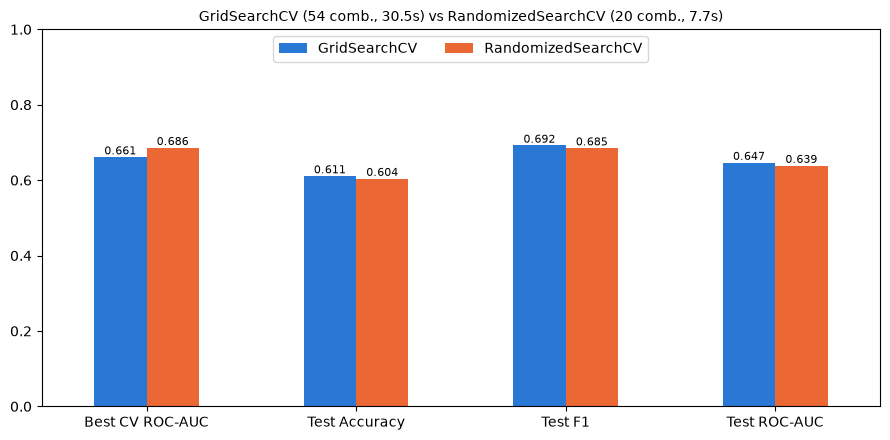

In [6]:
# Plot: metrics by search method
metrics = [f"best_cv_{SCORING}", "test_Accuracy", "test_F1", "test_ROC-AUC"]
ax = res.set_index("method")[metrics].T.plot(kind="bar", figsize=(9, 4.5), rot=0, color=["#2a78d6", "#eb6834"])
ax.set_xticklabels(["Best CV ROC-AUC", "Test Accuracy", "Test F1", "Test ROC-AUC"])
ax.set_ylim(0, 1)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.3f", fontsize=8)
ax.set_title(" vs ".join(f"{r.method} ({r.n_combinations} comb., {r.seconds}s)" for r in res.itertuples()),
             fontsize=10)
ax.legend(loc="upper center", ncol=2)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_appendix_search_comparison.png", dpi=200)
plt.show()